# 01. EDA: Yambda-50M

**Цель ноутбука** — понять данные настолько, чтобы обоснованно принять решения для всех экспериментов (E0–E2):

1. как устроено время и на какой период можно опираться;
2. что считать **кандидатом** (что ранжируем) и что считать **label** (что предсказываем);
3. какой **баланс классов** — от него зависит выбор функции потерь;
4. есть ли в истории сигнал для признаков (повторные прослушивания, артисты);
5. как формировать **группы** для ранжирующих метрик (NDCG@K, Recall@K);
6. как **разбить данные по времени** на train / val-A / val-B / test.

**Ограничение по памяти:** полный файл событий в памяти занимает ~4 ГБ из ~7.6 ГБ доступных.
Поэтому читаем данные лениво (`polars.LazyFrame`) и берём только нужные колонки.
Функции загрузки лежат в `src/data.py` и общие для всех ноутбуков.

In [ ]:
import sys, time
from pathlib import Path

#чтобы работало from src
ROOT = Path.cwd().resolve().parents[0] if Path.cwd().name == "notebooks" else Path.cwd()
#добавляем в начало списка поиска
sys.path.insert(0, str(ROOT))

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display

from src.data import (scan_events, scan_listens, scan_artist_map, scan_album_map,
                      EVENTS_PATH, ARTIST_PATH, ALBUM_PATH, DAY, HOUR, LAST_TIMESTAMP, LISTEN_THRESHOLD)

#показываем до 20 строк
pl.Config.set_tbl_rows(20)
# чтобы числа сложные читались лучше
pl.Config.set_thousands_separator(" ")
plt.rcParams.update({"figure.dpi": 110, #четкость графика
                     "axes.grid": True, #сетка на всех графиках
                       "grid.alpha": 0.3}) # сетка бледная, не мешает

## 1. Объём и схема данных

Используем файл `multi_event.parquet`: в нём все типы событий в одной таблице.

In [ ]:
# аналог select count(*)
n_rows = scan_events().select(pl.len()).collect().item()
# число преобразовано в число python, поэтому настройку set_thouds_... не работает
print(f"Строк (событий): {n_rows:,}".replace(",", " "))
print(f"Размер файла на диске: {EVENTS_PATH.stat().st_size / 1e6:.0f} МБ")
scan_events().collect_schema()

Строк (событий): 47 790 449
Размер файла на диске: 384 МБ


Schema([('uid', UInt32),
        ('timestamp', UInt32),
        ('item_id', UInt32),
        ('is_organic', UInt8),
        ('played_ratio_pct', UInt16),
        ('track_length_seconds', UInt32),
        ('event_type',
         Enum(categories=['listen', 'dislike', 'like', 'undislike', 'unlike']))])

## 2. В каких единицах время?

README датасета говорит timestamp binned into 5s units. 
- единица = 5 секунд, тогда реальное время = `timestamp × 5`;
-  это секунды, округлённые до 5.

Проверка: 
- если верно (б), все значения кратны 5, а длина периода совпадает с заявленной в статье (~10 месяцев).

timestamp - время от начала датасета

In [ ]:
ts = scan_events(["timestamp"]).select(
    #без alias было бы timestamo и duplicate error
    pl.col("timestamp").min().alias("min"),
    pl.col("timestamp").max().alias("max"),
    (pl.col("timestamp") % 5 != 0).sum().alias("не кратно 5"),
).collect()

display(ts)

span = ts["max"][0] - ts["min"][0]
print(f"Если единица = 5 с:  {span * 5 / DAY:.0f} дней")
print(f"Если единица = 1 с:  {span / DAY:.1f} дней")

min,max,не кратно 5
u32,u32,u32
0,26 000 000,0


Если единица = 5 с:  1505 дней
Если единица = 1 с:  300.9 дней


- все значения кратны 5
- данные собраны за 10 месяцев, что деает применро 301 день как и во второй строке
**=> 301 день, по 1 секунде**



- на времени держатся окна признаков и разбиение - ВАЖНО
- будем брать в признаки события СТРОГО меньше `< timestamp`, так как события **в одном 5-секундном интервале имеют одинаковое время**
     округление до 5 секунд означает, что время записано не точно, несколько событий в одно время

     
- ПОРЯДОК СТРОК с однаковым временем- СЛУЧАЙНЫЙ - код не должен опираться - раньше строка - раньше случилось

## 2a. `timestamp` — начало или конец прослушивания?

*(Пункт добавлен после того, как в E1 обнаружилась утечка)*

- если `timestamp` — **окончание** прослушивания, то промежуток между соседними событиями пользователя
совпадает с длительностью **текущего** прослушивания (`played_ratio × длина трека`) => признак, "сколько времени прошло с прошлого события" будет подсказкой из будущего
-  если **начало** — с длительностью **предыдущего**.
Берём пары соседних прослушиваний с промежутком до 15 минут (непрерывное прослушивание).

In [ ]:
      #какие колонки
L2 = (scan_listens(["uid", "timestamp", "played_ratio_pct", "track_length_seconds"])
      # часть польлзователей и сортируем по id и времени
      .filter(pl.col("uid") < 120_000).collect().sort("uid", "timestamp")
      
      .with_columns(dur=pl.col("played_ratio_pct") / 100 * pl.col("track_length_seconds"),
                    #разница с прошлым значением в таблице, сморим по id
                    gap=pl.col("timestamp").cast(pl.Int64).diff().over("uid"))
      .with_columns(prev_dur=pl.col("dur").shift(1).over("uid"))
      #промежуток от 1 до 15 минут - непрерывное прослушивание подряд
      .filter(pl.col("gap").is_between(1, 900)))


rows = []
for col, name in [("dur", "текущего"), ("prev_dur", "предыдущего")]:
    d = (L2["gap"] - L2[col]).abs()
    rows.append({"промежуток сравниваем с длительностью": name,
                  "медиана |разницы|, с": round(d.median(), 1),
                 "доля пар с разницей ≤ 10 с": round((d <= 10).mean(), 3),
                 # матрица 2 на 2, симметричная, возьмем [0,1] / [1,0] dur corr gap
                 "корреляция": round(np.corrcoef(L2["gap"], L2[col])[0, 1], 3)})

print(f"Пар соседних прослушиваний: {L2.height:,}".replace(",", " "))
display(pl.DataFrame(rows))
del L2

Пар соседних прослушиваний: 4 055 008


промежуток сравниваем с длительностью,"медиана |разницы|, с",доля пар с разницей ≤ 10 с,корреляция
str,f64,f64,f64
"""текущего""",3.2,0.77,0.7
"""предыдущего""",45.9,0.248,0.379


- обрезка до 15 минут, что либо слушал подряд, либо что-то длинное - с запасом
- разница три часа ни о чем не говорит, ушел поесть человек и поработть
- медиана: типичное расхождение промежутка и длительности
- корреляция - промежуток растет вместе с длительностью?

**Вывод: `timestamp` — момент ОКОНЧАНИЯ прослушивания.** Промежуток между соседними событиями совпадает с длительностью *текущего* прослушивания.

Следствия:
- признак «сколько времени прошло с предыдущего события» = длительность текущего прослушивания ≈ ответ (пропустил сразу или дослушал) — **утечка**, такие признаки запрещены
- «текущий момент» для признаков — это **начало** прослушивания, т.е. окончание предыдущего; дневные признаки (история до начала дня) это не затрагивает
- лайк, поставленный **во время** прослушивания, имеет timestamp **меньше** timestamp прослушивания — это важно для  №8

## 3. Типы событий и органика

какие действия были направлены на треки
- которые пользователь сам выбрал `org = 1`
- которые дала рек система `org = 0`

event_type,рекомендации (0),органика (1)
enum,u32,u32
"""listen""",22 463 555,24 003 657
"""dislike""",51 788,55 988
"""like""",379 255,502 201
"""undislike""",2 324,18 709
"""unlike""",16 531,296 441


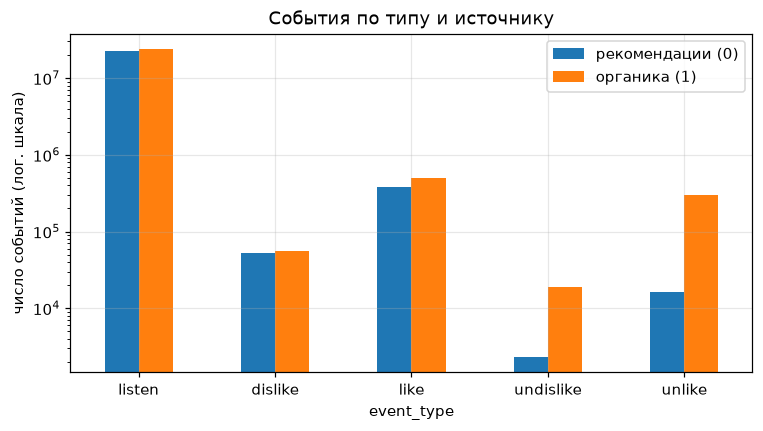

In [5]:
ev = (scan_events(["event_type", "is_organic"])
      .group_by("event_type", "is_organic").len().collect()
      .pivot(on="is_organic", index="event_type", values="len")
      .rename({"0": "рекомендации (0)", "1": "органика (1)"})
      .sort("event_type"))
display(ev)

ax = ev.to_pandas().set_index("event_type").plot.bar(logy=True, figsize=(8, 4), rot=0)
ax.set_ylabel("число событий (лог. шкала)")
ax.set_title("События по типу и источнику")
plt.show()

## 4. Пользователи

Сколько прослушиваний у пользователя и какая доля из них пришла из рекомендаций.
-  у всех ли пользователей достаточно истории для признаков?

statistic,uid,n_listens,share_reco
str,f64,f64,f64
"""count""",9 238.0,9 238.0,9 238.0
"""null_count""",0.0,0.0,0.0
"""mean""",500 736.696255,5 030.007794,0.459522
"""std""",288 241.028078,5 520.14541,0.309514
"""min""",100.0,6.0,0.0
"""25%""",251 500.0,937.0,0.18695
"""50%""",501 700.0,3 024.0,0.457092
"""75%""",750 300.0,7 182.0,0.707301
"""max""",1e6,27 617.0,1.0


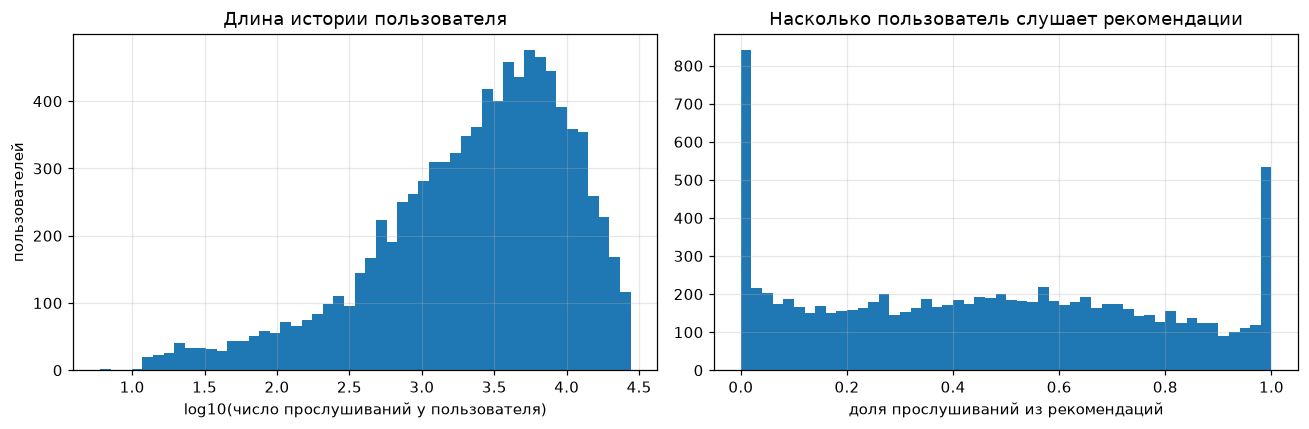

In [ ]:
users = (scan_listens(["uid", "is_organic"]).group_by("uid")
         .agg(pl.len().alias("n_listens"),
               (1 - pl.col("is_organic").cast(pl.Float32).mean())
                                                  .alias("share_reco"))
         .collect())

display(users.describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log10(users["n_listens"].to_numpy()), bins=50)
axes[0].set_xlabel("log10(число прослушиваний у пользователя)")
axes[0].set_ylabel("пользователей")
axes[0].set_title("Длина истории пользователя")
axes[1].hist(users["share_reco"].to_numpy(), bins=50)
axes[1].set_xlabel("доля прослушиваний из рекомендаций")
axes[1].set_title("Насколько пользователь слушает рекомендации")
plt.tight_layout()
plt.show()

- без истории - выбрасываем
- если слушает только рекомендации и будут признаки, связанные с  "выбирает сам" - там будет пусто, LightGBM умеет работать с Nan
- если история разной длины, скорее это надо будет учитывать и делать счетсчики

## 5. Треки: длинный хвост популярности

Распределение популярности треков определяет, насколько полезны признаки трека: у трека с 1–2 прослушиваниями статистика шумная.

Треков с прослушиваниями: 877 168
Треков ровно с 1 прослушиванием: 35.7%
Треков с < 10 прослушиваниями:  71.5%
Доля прослушиваний у топ-1% треков: 49.2%


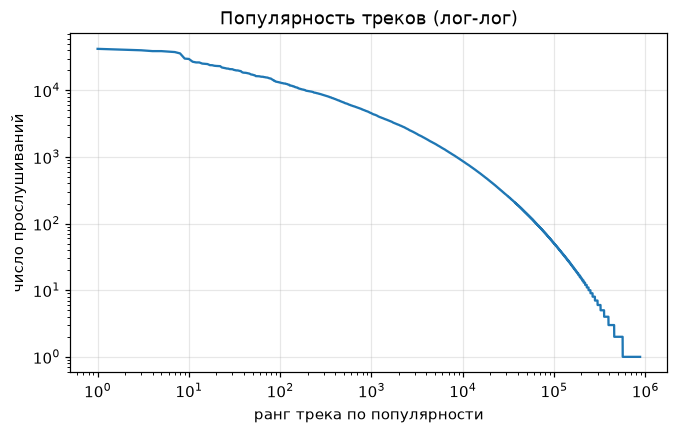

In [ ]:
items = scan_listens(["item_id"]).group_by("item_id").len().collect().sort("len", descending=True)
cnt = items["len"].to_numpy()
top1 = cnt[: max(1, len(cnt) // 100)].sum() / cnt.sum()
print(f"Треков с прослушиваниями: {len(cnt):,}".replace(",", " "))
print(f"Треков ровно с 1 прослушиванием: {(cnt == 1).mean():.1%}")
print(f"Треков с < 10 прослушиваниями:  {(cnt < 10).mean():.1%}")
#какую долю всех прослушаивание набрали те треки, которые входят в хит, топ 1%
print(f"Доля прослушиваний у топ-1% треков: {top1:.1%}")

plt.figure(figsize=(7, 4))
plt.loglog(np.arange(1, len(cnt) + 1), cnt)
plt.xlabel("ранг трека по популярности")
plt.ylabel("число прослушиваний")
plt.title("Популярность треков (лог-лог)")
plt.show()

- половину всего, что слушают 10 тыс пользователей, дают меньше 9 тыс треков
- остальные 870 тыс делают вторую половину

=> *длинный хвост* просулашиваний

## 6. Активность во времени

Проверяем, стабильны ли данные во времени: нет ли провалов, резких скачков, трендов.
- train, val и test должны быть похожи по природе.

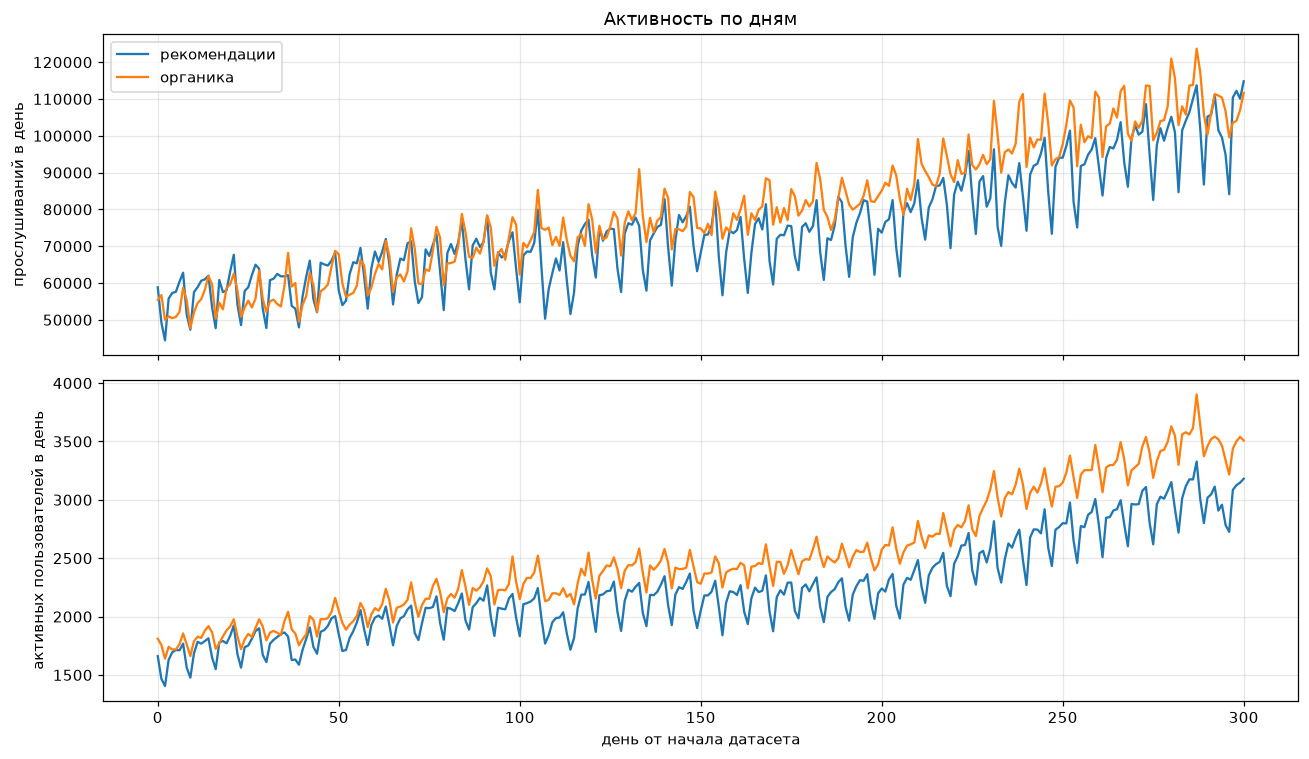

In [ ]:
daily = (scan_listens(["timestamp", "uid", "is_organic"])
         .with_columns((pl.col("timestamp") // DAY).alias("day"))
         .group_by("day", "is_organic")
         .agg(pl.len().alias("n"), pl.col("uid").n_unique().alias("users"))
         .collect().sort("day"))

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for org, name in [(0, "рекомендации"), (1, "органика")]:
    d = daily.filter(pl.col("is_organic") == org)
    axes[0].plot(d["day"], d["n"], label=name)
    axes[1].plot(d["day"], d["users"], label=name)

    
axes[0].set_ylabel("прослушиваний в день")
axes[0].legend()
axes[1].set_ylabel("активных пользователей в день")
axes[1].set_xlabel("день от начала датасета")
axes[0].set_title("Активность по дням")
plt.tight_layout()
plt.show()

- провалы +- 7  дней => сезонность
- устойчивый рост
- провалов нет


- тут и есть ответ на вопрос в задании, почему 7, а не 10 дней, -Ю **СЕЗОННОСТЬ**
- раз сезонность такова, то окна можно выбирать кратные 7
- части val и test берем по 7 дней, чтобы в каждую неделю попала нужная статистика
- будет дрейф => обучаться лучше на свежем, окно небольшое

## 7. Какую долю трека дослушивают: `played_ratio_pct`

Это главный кандидат на **label**
-  Смотрим распределение отдельно для рекомендаций и органики
и долю прослушиваний выше разных порогов
- Официальный бенчмарк Yambda считает трек прослушанным при `played_ratio_pct ≥ 50`

min,max,пропусков,> 100
u16,u16,u32,u32
0,159,0,218 145


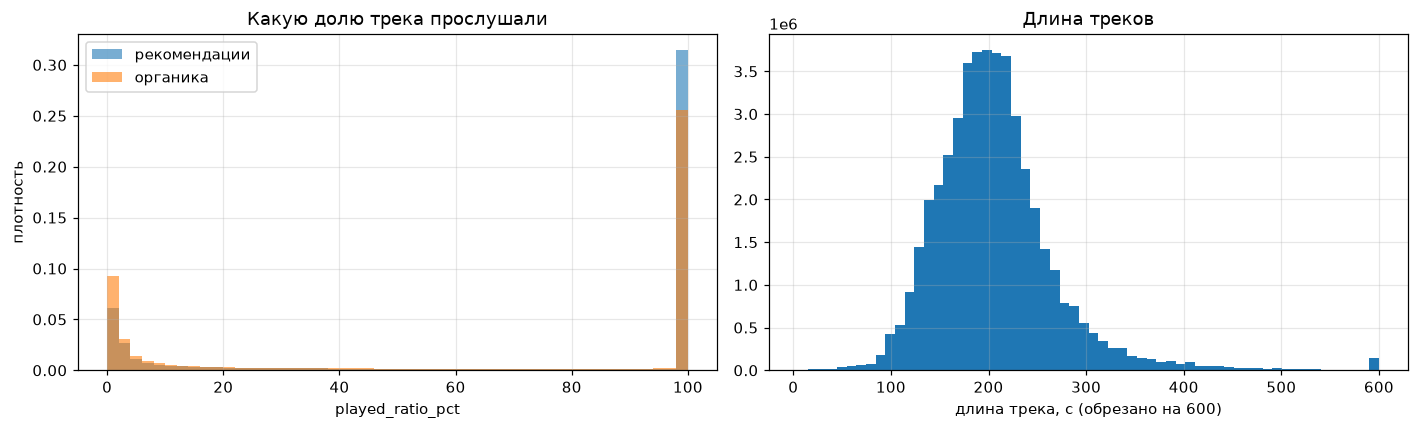

is_organic,>= 10,>= 30,>= 50,>= 80,>= 90,>= 100
u8,f64,f64,f64,f64,f64,f64
0,0.776138,0.715416,0.681884,0.64766,0.637166,0.587116
1,0.693961,0.627594,0.588316,0.542714,0.527103,0.490073


In [9]:
pr = scan_listens(["is_organic", "played_ratio_pct", "track_length_seconds"]).collect()
display(pr.select(pl.col("played_ratio_pct").min().alias("min"),
                  pl.col("played_ratio_pct").max().alias("max"),
                  pl.col("played_ratio_pct").null_count().alias("пропусков"),
                  (pl.col("played_ratio_pct") > 100).sum().alias("> 100")))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for org, name in [(0, "рекомендации"), (1, "органика")]:
    v = pr.filter(pl.col("is_organic") == org)["played_ratio_pct"].clip(0, 100).to_numpy()
    axes[0].hist(v, bins=np.arange(0, 102, 2), density=True, alpha=0.6, label=name)
axes[0].set_xlabel("played_ratio_pct")
axes[0].set_ylabel("плотность")
axes[0].legend()
axes[0].set_title("Какую долю трека прослушали")

lens = pr["track_length_seconds"].to_numpy()
axes[1].hist(np.clip(lens, 0, 600), bins=60)
axes[1].set_xlabel("длина трека, с (обрезано на 600)")
axes[1].set_title("Длина треков")
plt.tight_layout()
plt.show()

thr = [10, 30, 50, 80, 90, 100]
display(pr.group_by("is_organic").agg(
    [(pl.col("played_ratio_pct") >= t).mean().alias(f">= {t}") for t in thr]).sort("is_organic"))
del pr, users, items

- можно сказать - бимодальное распределение
        - либо слушаем
        - либо вырубаем

- порог оставим 50% - офиц порог датасета

## 8. Лайки: можно ли добавить их в label?

- нам надо: обучить модель, чтобы она предсказала реакцию пользователя и давала то, что ему понравиться
- лайки - звучит как хороший признак положительного ответа

**НРАВИТСЯ = ПРОСЛУШАЛ или ЛАЙКНУЛ**


Смотрим, сколько дослушиваний сопровождаются лайком и сколько лайков приходится на недослушанные треки:
если вторых почти нет, лайки label почти не меняют.

**Как связываем лайк с прослушиванием.** Лайк засчитывается, если он поставлен **с начала прослушивания до часа после его окончания**.
Начало = `timestamp − played_ratio × длина трека` (timestamp — окончание, см. §2a).

*Исправление:* в первой версии искался лайк только в течение часа **после** timestamp. Так терялись лайки, поставленные во время прослушивания
(а это 44% лайков: проверено при поиске утечки).

In [10]:
t0 = time.time()
reco = (scan_listens(["uid", "item_id", "timestamp", "is_organic", "played_ratio_pct", "track_length_seconds"])
        .filter(pl.col("is_organic") == 0).drop("is_organic")
        .collect()
        # начало прослушивания; Int64, чтобы разности времени могли быть отрицательными
        .with_columns(_start=pl.col("timestamp").cast(pl.Int64)
                      - (pl.col("played_ratio_pct").clip(0, 100) / 100 * pl.col("track_length_seconds")).cast(pl.Int64) - 5)
        .sort("_start"))
likes = (scan_events(["uid", "item_id", "timestamp", "event_type"])
         .filter(pl.col("event_type") == "like")
         .select("uid", "item_id", pl.col("timestamp").cast(pl.Int64).alias("like_ts"))
         .collect().sort("like_ts"))

# первый лайк после начала прослушивания; засчитываем, если он не позже часа после окончания
reco = reco.join_asof(likes, left_on="_start", right_on="like_ts", by=["uid", "item_id"],
                      strategy="forward", check_sortedness=False)
reco = reco.with_columns(
    full=(pl.col("played_ratio_pct") >= LISTEN_THRESHOLD),
    liked=(pl.col("like_ts") <= pl.col("timestamp").cast(pl.Int64) + HOUR).fill_null(False),
).drop("like_ts", "_start", "track_length_seconds").sort("timestamp")
del likes
print(f"Рекомендательных прослушиваний: {reco.height:,}  ({time.time() - t0:.0f} c)".replace(",", " "))

ct = reco.group_by("full", "liked").len().with_columns((pl.col("len") / reco.height).alias("доля")).sort("full", "liked")
display(ct)

Рекомендательных прослушиваний: 22 463 555  (2 c)


full,liked,len,доля
bool,bool,u32,f64
false,false,6 992 687,0.31129
false,true,153 320,0.006825
true,false,15 068 547,0.6708
true,true,249 001,0.011085


- лайки не особо что-то показывают 

## 9. Label и баланс классов

`label = 1`, если рекомендованный трек дослушан (`played_ratio_pct ≥ 50`) или лайкнут с начала прослушивания до часа после его окончания.

От баланса классов зависит выбор функции потерь:
- если положительных 20–80%, обычный бинарный logloss подходит без весов;
- если положительных единицы процентов, нужно думать о весах или о focal loss.

Также проверяем, **стабилен ли** баланс во времени (иначе модель, обученная на прошлом, будет смещена на тесте)
и насколько он **разный у пользователей** (если сильно разный — признаки пользователя будут важны).

Доля label = 1: 68.9%


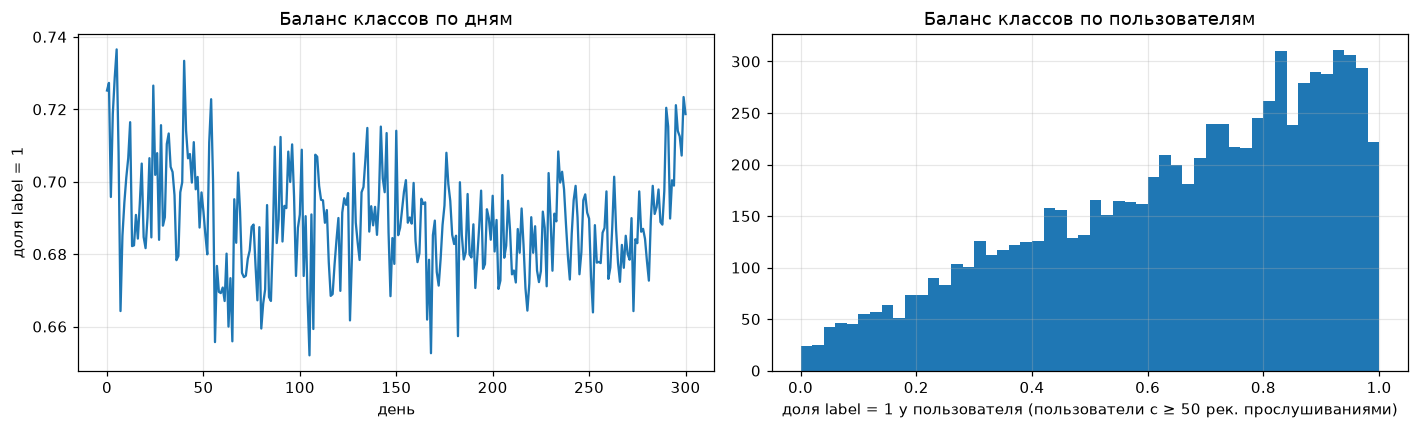

q10,q25,q50,q75,q90
f64,f64,f64,f64,f64
0.274518,0.464049,0.695039,0.859722,0.941489


In [11]:
reco = reco.with_columns(label=(pl.col("full") | pl.col("liked")).cast(pl.Int8))
print(f"Доля label = 1: {reco['label'].mean():.1%}")

day_pos = (reco.group_by((pl.col("timestamp") // DAY).alias("day"))
           .agg(pl.col("label").mean().alias("pos_rate"), pl.len().alias("n")).sort("day"))
user_pos = (reco.group_by("uid").agg(pl.col("label").mean().alias("pos_rate"), pl.len().alias("n"))
            .filter(pl.col("n") >= 50))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(day_pos["day"], day_pos["pos_rate"])
axes[0].set_xlabel("день")
axes[0].set_ylabel("доля label = 1")
axes[0].set_title("Баланс классов по дням")
axes[1].hist(user_pos["pos_rate"].to_numpy(), bins=50)
axes[1].set_xlabel("доля label = 1 у пользователя (пользователи с ≥ 50 рек. прослушиваниями)")
axes[1].set_title("Баланс классов по пользователям")
plt.tight_layout()
plt.show()
display(user_pos.select(pl.col("pos_rate").quantile(q).alias(f"q{int(q*100)}") for q in [0.1, 0.25, 0.5, 0.75, 0.9]))

## 10. Есть ли сигнал в истории? Повторные прослушивания и артисты

Это предварительная проверка будущих признаков **пары user–item**:
- **прямая связь** — слушал ли пользователь этот трек раньше;
- **косвенная связь** — слушал ли он раньше этого артиста

Для каждой пары (пользователь, трек) и (пользователь, артист) находим момент **первого** прослушивания по всей истории
(органика + рекомендации). Рекомендательное прослушивание считается «повторным», если оно позже первого
Здесь используется только прошлое относительно каждого события, так что утечки нет

Уникальных пар user–track:  13 268 889
Уникальных пар user–artist: 5 751 801


(9 c)
Рек. прослушиваний трека без артиста в справочнике: 0.01%


seen_track,seen_artist,n,доля label = 1,доля строк
bool,bool,u32,f64,f64
false,false,3 833 784,0.642655,0.170667
false,true,4 806 121,0.68108,0.213952
true,false,404,0.60396,0.000018
true,true,13 823 246,0.704138,0.615363


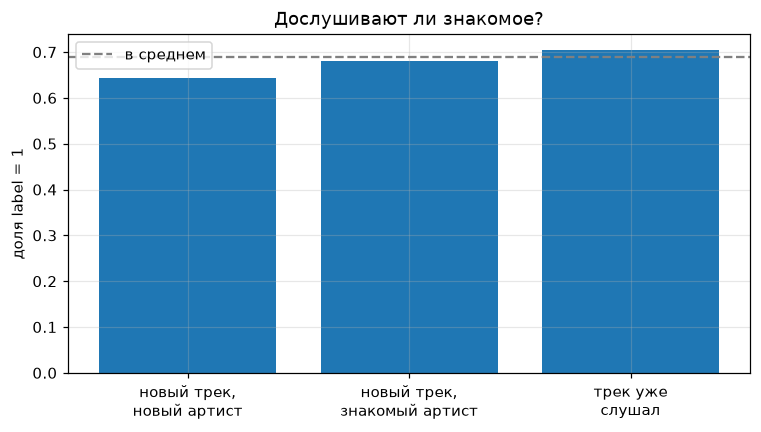

In [ ]:
t0 = time.time()
amap = scan_artist_map().collect()
first_track = (scan_listens(["uid", "item_id", "timestamp"]).group_by("uid", "item_id")
               .agg(pl.col("timestamp").min().alias("first_track_ts")).collect(engine="streaming"))
first_artist = (scan_listens(["uid", "item_id", "timestamp"]).join(amap.lazy(), on="item_id", how="left")
                .group_by("uid", "artist_id").agg(pl.col("timestamp").min().alias("first_artist_ts"))
                .collect(engine="streaming"))
print(f"Уникальных пар user–track:  {first_track.height:,}".replace(",", " "))
print(f"Уникальных пар user–artist: {first_artist.height:,}".replace(",", " "))


reco = (reco.join(amap, on="item_id", how="left")
        .join(first_track, on=["uid", "item_id"], how="left")
        .join(first_artist, on=["uid", "artist_id"], how="left")
        .with_columns(seen_track=(pl.col("timestamp") > pl.col("first_track_ts")).fill_null(False),
                      # трек без артиста в справочнике считаем "артист не знаком"
                      seen_artist=(pl.col("timestamp") > pl.col("first_artist_ts")).fill_null(False))
        .drop("first_track_ts", "first_artist_ts"))
del first_track, first_artist
print(f"({time.time() - t0:.0f} c)")
print(f"Рек. прослушиваний трека без артиста в справочнике: {reco['artist_id'].is_null().mean():.2%}")


rep = (reco.group_by("seen_track", "seen_artist")
       .agg(pl.len().alias("n"), pl.col("label").mean().alias("доля label = 1"))
       .with_columns((pl.col("n") / reco.height).alias("доля строк"))
       .sort("seen_track", "seen_artist"))
display(rep)

names = {(False, False): "новый трек,\nновый артист", (False, True): "новый трек,\nзнакомый артист",
         (True, True): "трек уже\nслушал", (True, False): "трек слушал,\nартист новый (?)"}
r = rep.filter(pl.col("n") > 1000)


plt.figure(figsize=(8, 4))
plt.bar([names[(a, b)] for a, b in zip(r["seen_track"], r["seen_artist"])], r["доля label = 1"])
plt.axhline(reco["label"].mean(), color="gray", ls="--", label="в среднем")
plt.ylabel("доля label = 1")
plt.title("Дослушивают ли знакомое?")
plt.legend()
plt.show()

- рек система в основном ставит знакомое
- знакомое дослушивают чаще, но на намного

слушал раньше
- любим и слушаем 20 раз
- не любим и пропускаем 10 раз подрядо
=> дргу друга гасит будут в среднем

=> можно сделать
- дослушал
- пропустил
- доля дослушаиваний этого артиста у пользователя

## 11. Группы для ранжирования

Метрики NDCG@K и Recall@K считаются **внутри группы** — набора треков, которые конкурировали за внимание пользователя
- **пользователь × день**;
- **сессия**: последовательность рекомендательных прослушиваний пользователя без пауз дольше 30 минут

Группа полезна для ранжирования, только если в ней есть и 0, и 1 (иначе порядок не важен, и NDCG тривиален)
Это же критично для LambdaRank: группы «все 0» или «все 1» не дают ему градиента

группа,групп,медиана размера,средний размер,доля групп с 0 и 1,доля строк в таких группах
str,i64,f64,f64,f64,f64
"""user × day""",672 923,20.0,33.4,0.741,0.872
"""сессия (30 мин)""",1 372 241,9.0,16.4,0.562,0.76


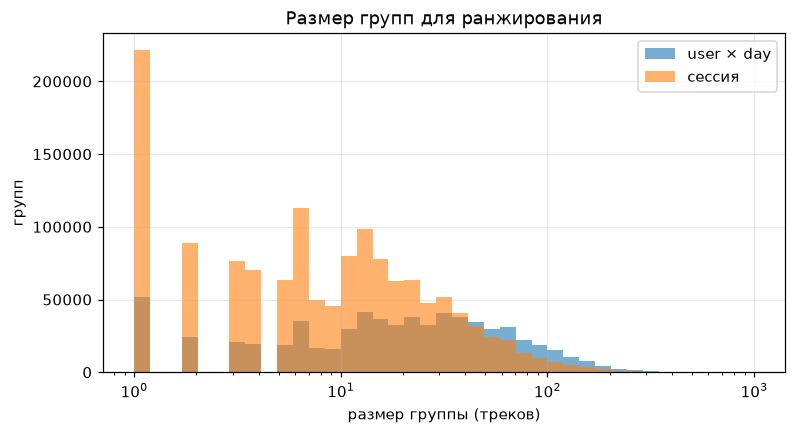

In [ ]:
reco = reco.sort("uid", "timestamp").with_columns(
    day=(pl.col("timestamp") // DAY).cast(pl.UInt16),
    session=((pl.col("timestamp").diff().over("uid").fill_null(10**9) > 30 * 60).cast(pl.UInt32).cum_sum()),
)

def group_stats(keys, name):
    g = reco.group_by(keys).agg(pl.len().alias("size"), pl.col("label").mean().alias("pos"))
    mixed = (g["pos"] > 0) & (g["pos"] < 1)
    return g, {"группа": name, "групп": g.height,
               "медиана размера": g["size"].median(), "средний размер": round(g["size"].mean(), 1),
               "доля групп с 0 и 1": round(mixed.mean(), 3),
               "доля строк в таких группах": round(g.filter(mixed)["size"].sum() / reco.height, 3)}

g_day, s_day = group_stats(["uid", "day"], "user × day")
g_ses, s_ses = group_stats(["session"], "сессия (30 мин)")
display(pl.DataFrame([s_day, s_ses]))

plt.figure(figsize=(8, 4))
bins = np.logspace(0, 3, 40)
plt.hist(g_day["size"].to_numpy(), bins=bins, alpha=0.6, label="user × day")
plt.hist(g_ses["size"].to_numpy(), bins=bins, alpha=0.6, label="сессия")
plt.xscale("log")
plt.xlabel("размер группы (треков)")
plt.ylabel("групп")
plt.legend()
plt.title("Размер групп для ранжирования")
plt.show()
del g_day, g_ses

=> пользователь * день, метрики ранжирования считаем по группа, где есть оба класса
- разнообразных групп больше
- строк больше
- медаина тоже больше

- если бы были все 0 -> порядок идельаный, NDCG = 1 пр любой модели
- все = 1 -> не определен NDCG

## 12. Артисты и альбомы

Косвенные признаки (пользователь × артист, пользователь × альбом) требуют связи трек → артист/альбом.
Проверяем покрытие и однозначность этой связи.

In [14]:
data_items = scan_listens(["item_id"]).unique()
raw_artist = pl.scan_parquet(ARTIST_PATH)
raw_album = pl.scan_parquet(ALBUM_PATH)

def mapping_stats(raw, name):
    per_item = raw.group_by("item_id").len()
    j = data_items.join(per_item, on="item_id", how="left").collect()
    return {"связь": name,
            "треков в данных": j.height,
            "покрытие": round(j["len"].is_not_null().mean(), 4),
            "доля треков с > 1 значением": round((j["len"] > 1).mean(), 4),
            "макс. значений на трек": j["len"].max()}

display(pl.DataFrame([mapping_stats(raw_artist, "трек → артист"), mapping_stats(raw_album, "трек → альбом")]))

per_artist = reco.group_by("artist_id").len()
print(f"Артистов среди рекомендательных прослушиваний: {per_artist.height:,}".replace(",", " "))

связь,треков в данных,покрытие,доля треков с > 1 значением,макс. значений на трек
str,i64,f64,f64,i64
"""трек → артист""",877 168,0.9936,0.0004,2
"""трек → альбом""",877 168,0.9989,0.2255,241


Артистов среди рекомендательных прослушиваний: 65 443


- у треков в 99% есть артист и почтив сегда один
- треки могут входить до 241 в разные альбомы
- СТРОИМ ЧЕРЕЗ **АРТИСТА**

## 13. План разбиения по времени

-  **история** : всё до начала train - только для расчёта признаков 
- **train** : 28 дней - обучение модели (строки = рекомендательные прослушивания) 
- **val-A** : 7 дней - отбор признаков, подбор гиперпараметров 
- **val-B** : 7 дней - подтверждение, что отбор не подогнан под val-A 
- **test** : последние 7 дней - итоговая оценка, **один раз** 

Между частями — зазор 30 минут, как в официальном бенчмарке, чтобы одна сессия не попала в две части.
Признаки для **любой** строки считаются только по событиям **до** её момента, поэтому вся история
(включая train и val) может использоваться как прошлое для более поздних частей.

Почему окна по 7 дней
-  у нас 10 тыс. пользователей, и одного дня мало для стабильной оценки NDCG
-  7 дней также усредняют возможную недельную сезонность.

часть,дни,строк,пользователей,доля label = 1,доля повторных треков,польз. с историей до train
str,str,i64,i64,f64,f64,f64
"""train""","""251.9 – 279.9""",2 667 547,7 334,0.682,0.623,0.924
"""val-A""","""279.9 – 286.9""",712 113,5 997,0.689,0.617,0.908
"""val-B""","""286.9 – 293.9""",725 211,6 282,0.7,0.611,0.912
"""test""","""293.9 – 300.9""",728 949,6 167,0.714,0.618,0.918


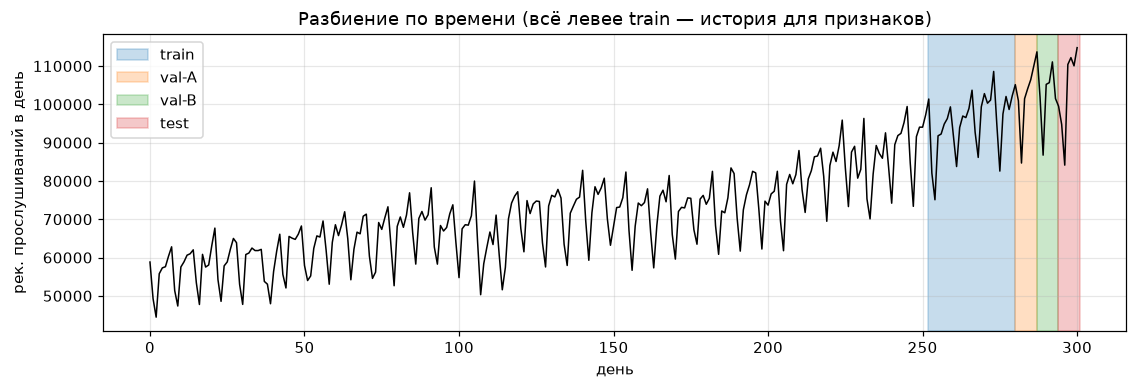

In [ ]:
GAP = HOUR // 2
W = 7 * DAY

test = (LAST_TIMESTAMP - W, LAST_TIMESTAMP + 1)
val_b = (test[0] - GAP - W, test[0] - GAP)
val_a = (val_b[0] - GAP - W, val_b[0] - GAP)
train = (val_a[0] - GAP - 28 * DAY, val_a[0] - GAP)
splits = {"train": train, "val-A": val_a, "val-B": val_b, "test": test}

part = pl.when(pl.lit(False)).then(pl.lit(None, dtype=pl.Utf8))
for name, (a, b) in splits.items():
    part = part.when((pl.col("timestamp") >= a) & (pl.col("timestamp") < b)).then(pl.lit(name))
reco = reco.with_columns(part=part)

hist_users = set(reco.filter(pl.col("timestamp") < train[0])["uid"].unique().to_list())
rows = []
for name, (a, b) in splits.items():
    p = reco.filter(pl.col("part") == name)
    rows.append({"часть": name, "дни": f"{a / DAY:.1f} – {b / DAY:.1f}", "строк": p.height,
                 "пользователей": p["uid"].n_unique(), "доля label = 1": round(p["label"].mean(), 3),
                 "доля повторных треков": round(p["seen_track"].mean(), 3),
                 "польз. с историей до train": round(np.mean([u in hist_users for u in p["uid"].unique().to_list()]), 3)})
display(pl.DataFrame(rows))


plt.figure(figsize=(12, 3.5))
plt.plot(day_pos["day"], day_pos["n"], color="black", lw=1)
colors = {"train": "tab:blue", "val-A": "tab:orange", "val-B": "tab:green", "test": "tab:red"}

for name, (a, b) in splits.items():
    plt.axvspan(a / DAY, b / DAY, alpha=0.25, color=colors[name], label=name)


plt.xlabel("день")
plt.ylabel("рек. прослушиваний в день")
plt.legend(loc="upper left")
plt.title("Разбиение по времени (всё левее train — история для признаков)")
plt.show()


## 14. Выводы и принятые решения

### Что узнали о данных
| # | Наблюдение | Следствие для проекта |
|---|---|---|
| 1 | `timestamp` — **секунды** (все значения кратны 5), период **≈ 301 день** | Окна признаков и разбиение задаём в секундах: `DAY = 86 400` |
| 1a | `timestamp` прослушивания — момент его **окончания**  | «Время с предыдущего события» = длительность текущего прослушивания +- ответ — такие признаки запрещены . «Текущий момент» для признаков — начало прослушивания |
| 2 | 47.8 млн событий? прослушиваний поровну из рекомендаций  и органики . Прослушивания есть у почти 99% пользователей | Кандидатов (рекомендательных прослушиваний) достаточно, можно брать окно train +_ 4 недели |
| 3 | Сильная **недельная сезонность** (провалы каждые 7 дней) и **рост** активности: к концу периода активных пользователей в +-2 раза больше | Части val/test берём кратными 7 дням. Рост данных означает, что train и test немного различаются (дрейф) |
| 4 | Длинный хвост: 36% треков прослушаны 1 раз, 72% меньше 10 раз, топ-1% треков дают 49% прослушиваний | Статистики трека шумные у редких треков, нужны счётчики «сколько данных», а не только доли |
| 5 | `played_ratio_pct` **бимодален**: трек либо пропускают в первые секунды, либо дослушивают до конца | Порог label почти не важен. Берём **официальный порог 50**. Значения > 100 при расчёте признаков обрезаем до 100 |
| 6 | Лайк без дослушивания — всего **0.68%** рекомендательных прослушиваний (лайк считается с начала прослушивания до часа после окончания) | Лайки почти не меняют label. Оставляем их в определении |
| 7 | **Доля label = 1 +- 68.9%**, по дням стабильна , к концу немного растёт  | Дисбаланс умеренный, веса классов не нужны. Рост доли к тесту может слегка испортить LogLoss (калибровку), но не AUC/NDCG. |
| 8 | **Пользователи очень разные**: доля дослушиваний у 10% пользователей < 27%, у 10% > 94% | Главный ожидаемый сигнал — признаки пользователя (его собственная доля пропусков). Проверим через SHAP  |
| 9 | 61.5% рекомендательных прослушиваний — **уже знакомые треки**, ещё 21% — знакомые артисты. Дослушивают знакомое чаще  | Прямые (user×track) и косвенные (user×artist) признаки имеют смысл, но разница умеренная. Интереснее будут счётчики **с исходом** (сколько раз дослушал/пропустил этого артиста), а не просто «слушал ли» |
| 10 | Группы **user × день** | Для NDCG / Recall и LambdaRank берём группы **user × день** |
| 11 | Связь трек → артист однозначна . Трек -> альбом неоднозначна: **22.5%** треков в нескольких альбомах | Косвенные признаки строим в первую очередь через **артиста**. Альбом — с осторожностью  |

### Решения
1. **Кандидаты:** рекомендательные прослушивания (`is_organic = 0`).
   **Label:** `played_ratio_pct ≥ 50` или лайк этого трека с начала прослушивания до часа после его окончания.
2. **Функция потерь:** при 68.9% положительных **основной — бинарный logloss без весов классов**, дополнительное сравнение — **LambdaRank** с группами user × день.
3. **Метрики:** LogLoss, ROC-AUC (по всем строкам), NDCG@10 и Recall@10 (внутри групп user × день, только группы, где есть и 0, и 1).
4. **Разбиение** (дни от начала датасета):

   | часть | дни |  доля label = 1 |
   |---|---|---|
   | история | 0 – 251.9 | только для признаков | — |
   | train | 251.9 – 279.9 | 0.682 |
   | val-A | 279.9 – 286.9 |  0.689 |
   | val-B | 286.9 – 293.9 |  0.700 |
   | test | 293.9 – 300.9 | 0.714 |

   Между частями зазор 30 минут. Около 8% пользователей в каждой части не имеют истории до начала train: на них проверим работу «холодного» сценария.
5. **Память:** весь пайплайн EDA уложился в ~5 ГБ пика. Для признаков работаем семействами и сохраняем результаты в parquet на диск.

### Открытые вопросы для E0
- Считать признаки **на момент каждого прослушивания** (точнее, учитывает происходящее в сессии) или **на начало дня** (проще и дешевле)? Это решим при построении E0 и проверим тестами на утечку в `00_checks.ipynb`.
